# 1. Project Introduction

## 1.1 Project Objective

The objective of this project is to perform Exploratory Data Analysis (EDA) on retail sales data to identify sales trends, understand customer purchasing behaviour, analyse product performance, and discover useful business insights.

## 1.2 Tools and Technologies

- Python
- Jupyter Notebook
- Pandas
- NumPy
- Matplotlib
- Seaborn

## 1.3 Project Overview

This project involves inspecting and analysing retail sales data using statistical methods and data visualisations. The analysis will help identify patterns, trends, and insights that can support business decision-making.

# 2. Importing Libraries

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


# 3. Loading the Dataset

In [2]:
# Define the dataset file path

file_path = "../dataset/Customer_Sales_Segmentation_Day2.xlsx"

# Read the Excel workbook

excel_file = pd.ExcelFile(file_path)

# Display available worksheets

print("Available Worksheets:")
print(excel_file.sheet_names)

Available Worksheets:
['Customers', 'Orders', 'Products', 'Regions', 'Targets', 'Project_Info']


In [3]:
# Load the main worksheets into DataFrames

customers = pd.read_excel(file_path, sheet_name="Customers")
orders = pd.read_excel(file_path, sheet_name="Orders")
products = pd.read_excel(file_path, sheet_name="Products")

print("Customers, Orders and Products datasets loaded successfully!")

Customers, Orders and Products datasets loaded successfully!


# 4. Task 1 – Initial Data Inspection

In [4]:
# Inspect dataset structure

datasets = {
    "CUSTOMERS": customers,
    "ORDERS": orders,
    "PRODUCTS": products
}

for name, df in datasets.items():

    print("\n", "=" * 50)
    print(name, "DATASET")
    print("=" * 50)

    # Dataset dimensions
    print("\nShape:", df.shape)

    # Column names and data types
    print("\nData Types:")
    print(df.dtypes)

    # Missing values
    print("\nMissing Values:")
    print(df.isnull().sum())


CUSTOMERS DATASET

Shape: (2000, 11)

Data Types:
Customer_ID                    object
Customer_Name                  object
Gender                         object
Age                             int64
Region_ID                      object
Customer_Segment               object
Acquisition_Channel            object
Membership_Level               object
City                           object
State                          object
Registration_Date      datetime64[ns]
dtype: object

Missing Values:
Customer_ID            0
Customer_Name          0
Gender                 0
Age                    0
Region_ID              0
Customer_Segment       0
Acquisition_Channel    0
Membership_Level       0
City                   0
State                  0
Registration_Date      0
dtype: int64

ORDERS DATASET

Shape: (20000, 9)

Data Types:
Order_ID                object
Order_Date      datetime64[ns]
Customer_ID             object
Product_ID              object
Quantity                 int64
Unit_Pric

# 5. Task 2 – Descriptive Statistical Analysis

In [5]:
# Function to calculate descriptive statistics

def descriptive_statistics(df):

    numerical_data = df.select_dtypes(include=np.number)

    summary = pd.DataFrame({
        "Mean": numerical_data.mean(),
        "Median": numerical_data.median(),
        "Mode": [
            numerical_data[column].mode().tolist()
            for column in numerical_data.columns
        ],
        "Standard Deviation": numerical_data.std()
    })

    return summary


# Customer statistics
print("CUSTOMER STATISTICS")
display(descriptive_statistics(customers))

# Orders statistics
print("ORDERS STATISTICS")
display(descriptive_statistics(orders))

# Product statistics
print("PRODUCT STATISTICS")
display(descriptive_statistics(products))

CUSTOMER STATISTICS


,Mean,Median,Mode,Standard Deviation
Age,41.37,41.0,[56],13.621853


ORDERS STATISTICS


,Mean,Median,Mode,Standard Deviation
Quantity,1.885000,2.00,[1],1.074073
Unit_Price,21656.520727,21442.34,[1927.37],13902.069160
Discount,0.083650,0.10,[0.05],0.066777


PRODUCT STATISTICS


,Mean,Median,Mode,Standard Deviation
Cost_Price,16588.7806,16378.950,"[441.89, 965.31, 1133.31, 1445.0, 1821.65, 186...",10337.757128
Selling_Price,22086.6561,22048.385,"[592.22, 1201.42, 1701.61, 1927.37, 2226.39, 2...",13916.545153


**Observations – Descriptive Statistical Analysis**

1. The average customer age is 41.37 years, with a median age of 41 years.
2. The average order quantity is approximately 1.89 units, while the median quantity is 2 units.
3. The average unit price is 21,656.52.
4. The average discount value is 0.08365. Its percentage interpretation will depend on the dataset's discount format.
5. The average product selling price (22,086.66) is higher than the average cost price (16,588.78).


### Supporting Data Verification


In [6]:
print("ORDER STATUS COUNTS")
print(orders["Order_Status"].value_counts())

print("\nDISCOUNT DETAILS")
print("Minimum discount:", orders["Discount"].min())
print("Maximum discount:", orders["Discount"].max())
print("Unique discount values:")
print(sorted(orders["Discount"].unique()))

print("\nORDER DATE RANGE")
print("Start date:", orders["Order_Date"].min())
print("End date:", orders["Order_Date"].max())

ORDER STATUS COUNTS
Order_Status
Completed    17187
Returned      1662
Cancelled     1151
Name: count, dtype: int64

DISCOUNT DETAILS
Minimum discount: 0.0
Maximum discount: 0.25
Unique discount values:
[np.float64(0.0), np.float64(0.05), np.float64(0.1), np.float64(0.15), np.float64(0.2), np.float64(0.25)]

ORDER DATE RANGE
Start date: 2025-01-01 00:00:00
End date: 2026-08-31 00:00:00


# 6. Task 3 – Monthly and Quarterly Sales Trends


### 6.1 Calculate Sales Revenue


In [7]:

# Filter completed orders
completed_orders = orders[orders["Order_Status"] == "Completed"].copy()

# Calculate revenue after discount
completed_orders["Revenue"] = (
    completed_orders["Quantity"]
    * completed_orders["Unit_Price"]
    * (1 - completed_orders["Discount"])
)

# Display the first five records
print("Completed Orders with Revenue:")
display(completed_orders[["Order_ID", "Order_Date", "Quantity",
                          "Unit_Price", "Discount", "Revenue"]].head())

# Display total revenue
print("\nTotal Sales Revenue:", round(completed_orders["Revenue"].sum(), 2))


Completed Orders with Revenue:


,Order_ID,Order_Date,Quantity,Unit_Price,Discount,Revenue
1,O00002,2026-05-09,2,10219.90,0.10,18395.8200
2,O00003,2026-03-04,2,22112.73,0.10,39802.9140
3,O00004,2026-02-04,1,34674.69,0.15,29473.4865
5,O00006,2025-01-29,1,21442.34,0.10,19298.1060
7,O00008,2026-08-26,1,17078.54,0.00,17078.5400



Total Sales Revenue: 643228128.21



### 6.2 Monthly Sales Analysis


In [8]:

# Group sales revenue by month
monthly_sales = (
    completed_orders
    .set_index("Order_Date")
    .resample("ME")["Revenue"]
    .sum()
)

# Display monthly sales
print("MONTHLY SALES REVENUE")
display(monthly_sales)


MONTHLY SALES REVENUE


Order_Date
2025-01-31    2.257497e+07
2025-02-28    2.222433e+07
2025-03-31    2.452611e+07
2025-04-30    2.507778e+07
2025-05-31    2.691844e+07
2025-06-30    2.562680e+07
2025-07-31    2.967168e+07
2025-08-31    3.079426e+07
2025-09-30    3.181950e+07
2025-10-31    3.348043e+07
2025-11-30    3.314778e+07
2025-12-31    3.630174e+07
2026-01-31    3.545191e+07
2026-02-28    3.248769e+07
2026-03-31    3.781911e+07
2026-04-30    3.629929e+07
2026-05-31    3.956178e+07
2026-06-30    3.826063e+07
2026-07-31    3.941581e+07
2026-08-31    4.176808e+07
Freq: ME, Name: Revenue, dtype: float64


### 6.3 Monthly Sales Trend – Line Chart


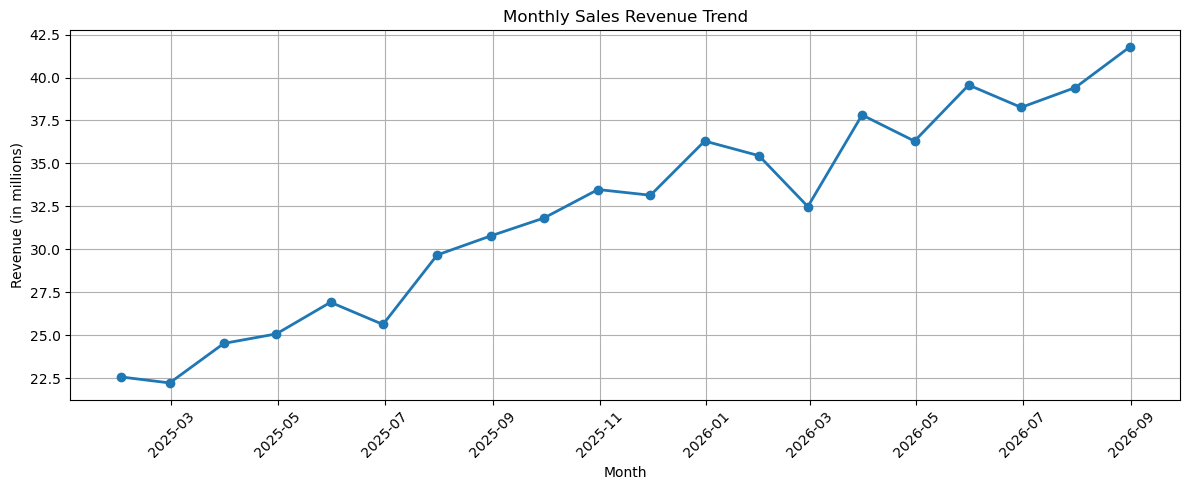

In [22]:

# Plot monthly sales trend
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (in millions)")

# Display revenue in millions
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x / 1e6:.1f}")
)

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.savefig("../charts/monthly_sales_trend.png",
            dpi=300, bbox_inches="tight")

plt.show()



**Observations – Monthly Sales Trend**

1. Monthly sales revenue shows an overall increasing trend from January 2025 to August 2026.
2. February 2025 recorded the lowest monthly revenue, at approximately ₹22.22 million.
3. August 2026 recorded the highest monthly revenue, at approximately ₹41.77 million.
4. Sales revenue experienced some fluctuations, particularly in July 2025 and March 2026.
5. Overall, the increasing trend indicates growth in sales revenue during the analysed period.



### 6.4 Quarterly Sales Analysis


In [10]:

# Group sales revenue by quarter
quarterly_sales = (
    completed_orders
    .set_index("Order_Date")
    .resample("QE")["Revenue"]
    .sum()
)

# Display quarterly sales revenue
print("QUARTERLY SALES REVENUE")
display(quarterly_sales.round(2))


QUARTERLY SALES REVENUE


Order_Date
2025-03-31    6.932542e+07
2025-06-30    7.762301e+07
2025-09-30    9.228544e+07
2025-12-31    1.029300e+08
2026-03-31    1.057587e+08
2026-06-30    1.141217e+08
2026-09-30    8.118389e+07
Freq: QE-DEC, Name: Revenue, dtype: float64


### 6.5 Quarterly Sales Trend – Line Chart


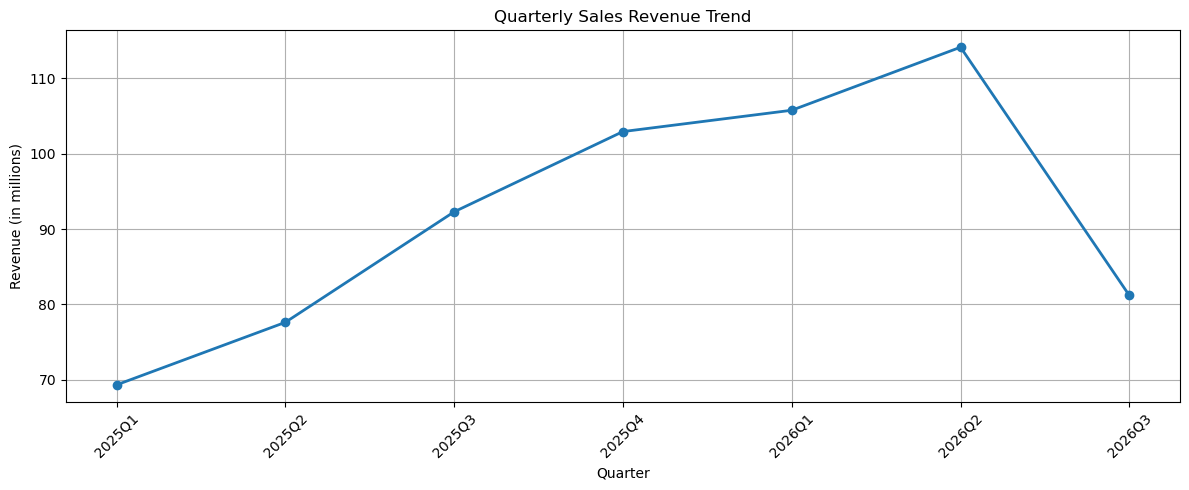

In [23]:

# Prepare quarterly labels
quarter_labels = quarterly_sales.index.to_period("Q").astype(str)

# Plot quarterly sales trend
plt.figure(figsize=(12, 5))

plt.plot(
    quarter_labels,
    quarterly_sales.values / 1e6,
    marker="o",
    linewidth=2
)

plt.title("Quarterly Sales Revenue Trend")
plt.xlabel("Quarter")
plt.ylabel("Revenue (in millions)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.savefig("../charts/quarterly_sales_trend.png",
            dpi=300, bbox_inches="tight")

plt.show()



**Observations – Quarterly Sales Trend**

1. Quarterly sales revenue shows an overall increasing trend from Q1 2025 to Q2 2026.
2. Q1 2025 recorded approximately ₹69.33 million in revenue.
3. Q2 2026 recorded the highest revenue among the complete quarters, at approximately ₹114.12 million.
4. Revenue increased consistently across the quarters from Q1 2025 to Q2 2026.
5. Q3 2026 recorded approximately ₹81.18 million; however, this quarter includes only July and August, so it is not directly comparable with complete quarters.



# 7. Task 4 – Customer Age and Gender Analysis



### 7.1 Customer Age Distribution


CUSTOMER AGE DISTRIBUTION
Minimum Age: 18
Maximum Age: 65
Average Age: 41.37


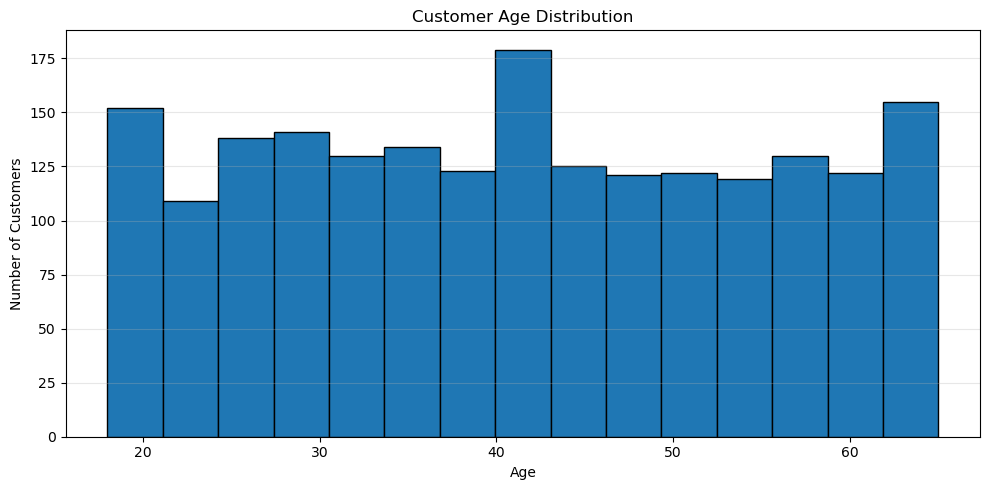

In [24]:

# Display customer age statistics
print("CUSTOMER AGE DISTRIBUTION")
print("Minimum Age:", customers["Age"].min())
print("Maximum Age:", customers["Age"].max())
print("Average Age:", round(customers["Age"].mean(), 2))

# Plot age distribution
plt.figure(figsize=(10, 5))

plt.hist(customers["Age"], bins=15, edgecolor="black")

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("../charts/customer_age_distribution.png",
            dpi=300, bbox_inches="tight")

plt.show()



**Observations – Customer Age Distribution**

1. The customers' ages range from 18 to 65 years.
2. The average customer age is 41.37 years.
3. The histogram shows that customers belong to different age groups.
4. A noticeable concentration of customers appears around the 40–43 age range.
5. The customer base includes both younger and older adults, indicating a diverse age distribution.



### 7.2 Customer Gender Distribution


CUSTOMER GENDER DISTRIBUTION


Gender
Male      1123
Female     877
Name: count, dtype: int64

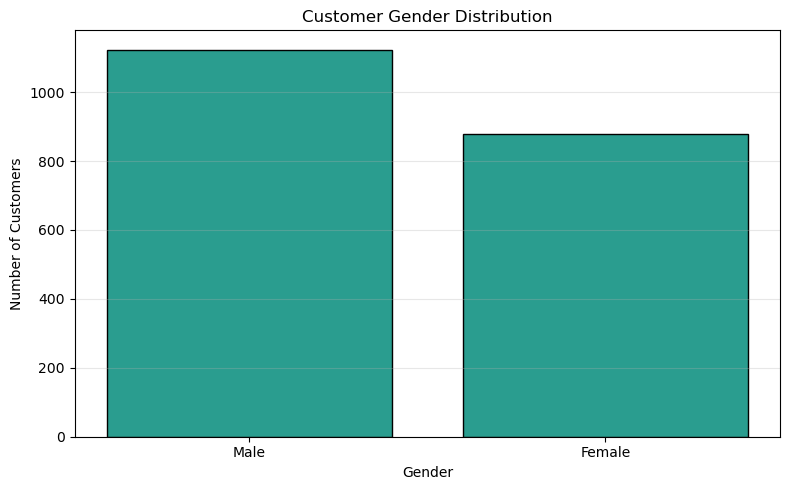

In [25]:

# Calculate gender distribution
gender_counts = customers["Gender"].value_counts()

print("CUSTOMER GENDER DISTRIBUTION")
display(gender_counts)

# Plot gender distribution
plt.figure(figsize=(8, 5))

plt.bar(gender_counts.index, gender_counts.values,
        color="#2A9D8F", edgecolor="black")

plt.title("Customer Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("../charts/customer_gender_distribution.png",
            dpi=300, bbox_inches="tight")

plt.show()



**Observations – Customer Gender Distribution**

1. The dataset contains 1,123 male customers and 877 female customers.
2. Male customers represent 56.15% of the total customer base.
3. Female customers represent 43.85% of the total customer base.
4. The number of male customers is higher than the number of female customers.
5. Overall, the customer base has a relatively balanced gender distribution, with a slight male majority.



# 8. Task 5 – Top 10 Best-Selling Products and Revenue by Category



### 8.1 Top 10 Best-Selling Products


In [14]:

# Calculate total quantity sold for each product
product_sales = (
    completed_orders
    .groupby("Product_ID")["Quantity"]
    .sum()
    .reset_index()
)

# Add product names
product_sales = product_sales.merge(
    products[["Product_ID", "Product_Name"]],
    on="Product_ID",
    how="left"
)

# Select the top 10 best-selling products
top_10_products = (
    product_sales
    .sort_values(by="Quantity", ascending=False)
    .head(10)
)

print("TOP 10 BEST-SELLING PRODUCTS")
display(top_10_products)


TOP 10 BEST-SELLING PRODUCTS


,Product_ID,Quantity,Product_Name
51,P052,546,UrbanX Appliances 2
0,P001,545,Nova Smartphones 1
32,P033,511,Prime Footwear 3
40,P041,506,Nova Kitchen 1
36,P037,493,Orbit Accessories 2
77,P078,492,Nexa Personal Care 3
99,P100,492,Zenith Equipment 5
42,P043,486,Prime Kitchen 3
76,P077,480,Orbit Personal Care 2
5,P006,479,Luma Audio 1



### 8.2 Top 10 Best-Selling Products – Bar Chart


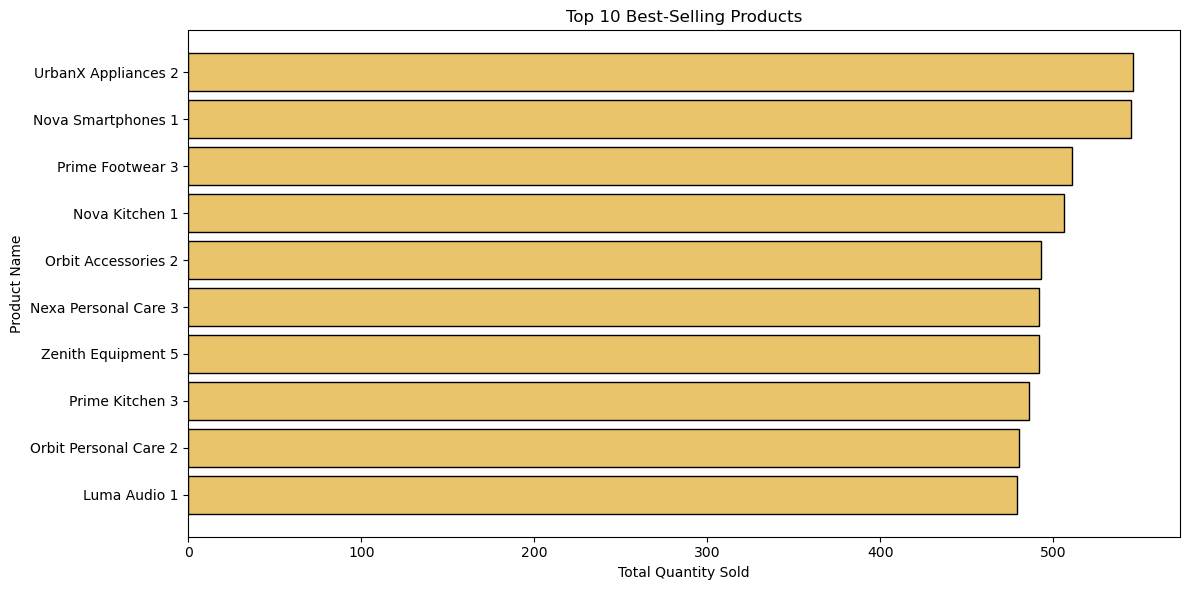

In [26]:

# Plot top 10 best-selling products
plt.figure(figsize=(12, 6))

plt.barh(
    top_10_products["Product_Name"],
    top_10_products["Quantity"],
    color="#E9C46A",
    edgecolor="black"
)

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product Name")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig("../charts/top_10_best_selling_products.png",
            dpi=300, bbox_inches="tight")

plt.show()



**Observations – Top 10 Best-Selling Products**

1. UrbanX Appliances 2 is the best-selling product, with 546 units sold.
2. Nova Smartphones 1 ranks second, with 545 units sold.
3. Prime Footwear 3 ranks third, with 511 units sold.
4. The top 10 products have sales quantities ranging from 479 to 546 units.
5. The sales quantities of the top 10 products are relatively close, indicating similar demand among these leading products.



### 8.3 Revenue by Product Category


In [16]:

# Combine completed orders with product categories
category_orders = completed_orders.merge(
    products[["Product_ID", "Category"]],
    on="Product_ID",
    how="left"
)

# Calculate total revenue by category
category_revenue = (
    category_orders
    .groupby("Category")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("REVENUE BY PRODUCT CATEGORY")
display(category_revenue.round(2))


REVENUE BY PRODUCT CATEGORY


Category
Home & Kitchen    1.601448e+08
Fashion           1.360255e+08
Beauty            1.190828e+08
Electronics       1.159386e+08
Sports            1.120364e+08
Name: Revenue, dtype: float64


### 8.4 Revenue by Product Category – Bar Chart


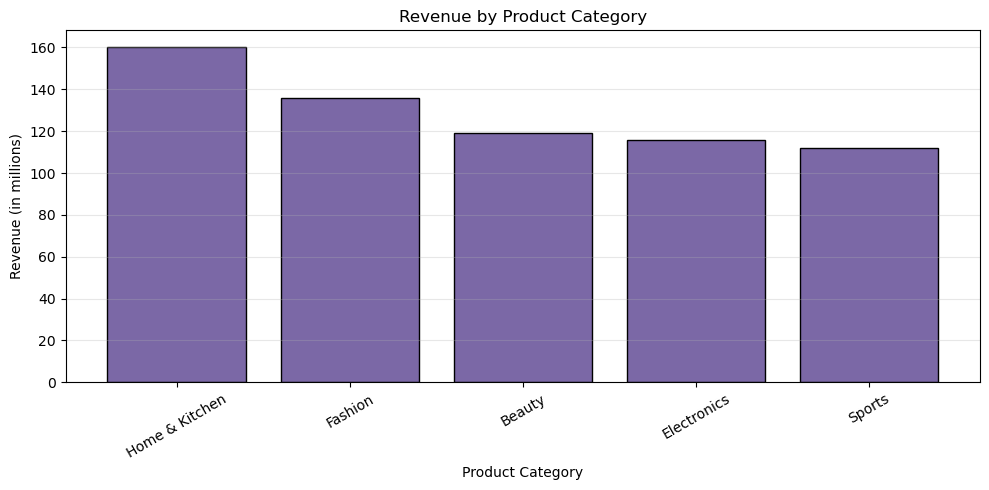

In [27]:

# Plot revenue by product category
plt.figure(figsize=(10, 5))

plt.bar(
    category_revenue.index,
    category_revenue.values / 1e6,
    color="#7B68A6",
    edgecolor="black"
)

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue (in millions)")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("../charts/revenue_by_product_category.png",
            dpi=300, bbox_inches="tight")

plt.show()



**Observations – Revenue by Product Category**

1. Home & Kitchen generates the highest revenue, approximately ₹160.14 million.
2. Fashion ranks second, generating approximately ₹136.03 million.
3. Beauty generates approximately ₹119.08 million.
4. Electronics and Sports generate approximately ₹115.94 million and ₹112.04 million, respectively.
5. Sports generates the lowest revenue among the five product categories.
6. Home & Kitchen is the leading revenue-generating category in the dataset.



# 9. Task 6 – Correlation Heatmap



### 9.1 Correlation Matrix


In [18]:

# Select numerical columns for correlation analysis
correlation_data = completed_orders[
    ["Quantity", "Unit_Price", "Discount", "Revenue"]
]

# Calculate correlation matrix
correlation_matrix = correlation_data.corr()

print("CORRELATION MATRIX")
display(correlation_matrix.round(2))


CORRELATION MATRIX


,Quantity,Unit_Price,Discount,Revenue
Quantity,1.00,-0.01,-0.00,0.60
Unit_Price,-0.01,1.00,-0.01,0.68
Discount,-0.00,-0.01,1.00,-0.09
Revenue,0.60,0.68,-0.09,1.00



### 9.2 Correlation Heatmap


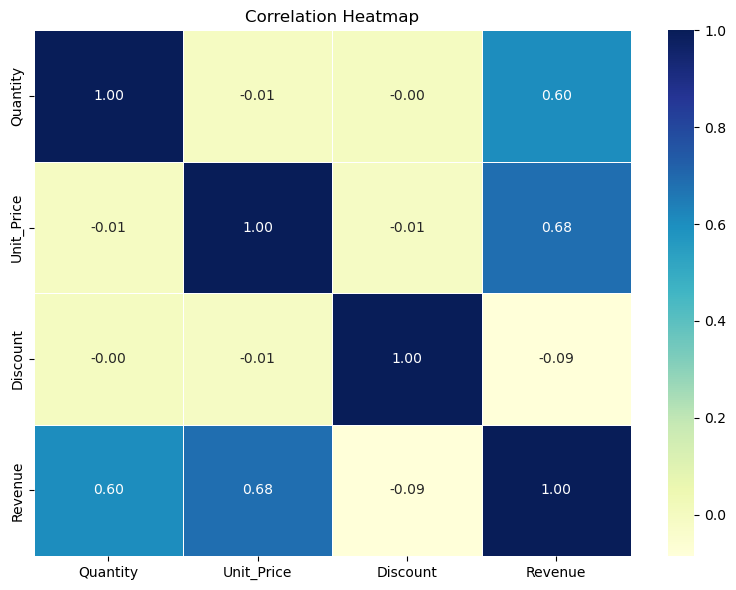

In [28]:

# Create correlation heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()

plt.savefig("../charts/correlation_heatmap.png",
            dpi=300, bbox_inches="tight")

plt.show()



**Observations – Correlation Heatmap**

1. Quantity and Revenue have a moderate positive correlation of 0.60.
2. Unit_Price and Revenue have a moderate positive correlation of 0.68.
3. Discount and Revenue have a very weak negative correlation of -0.09.
4. Quantity and Unit_Price have almost no linear correlation, with a value of -0.01.
5. Unit_Price has the strongest positive correlation with Revenue among the variables analysed.
6. Overall, the heatmap indicates that Quantity and Unit_Price have stronger positive relationships with Revenue than Discount.



# 10. Task 7 – Additional Visualisation



### 10.1 Revenue by Customer Segment


In [20]:

# Combine completed orders with customer segments
segment_orders = completed_orders.merge(
    customers[["Customer_ID", "Customer_Segment"]],
    on="Customer_ID",
    how="left"
)

# Calculate revenue by customer segment
segment_revenue = (
    segment_orders
    .groupby("Customer_Segment")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("REVENUE BY CUSTOMER SEGMENT")
display(segment_revenue.round(2))


REVENUE BY CUSTOMER SEGMENT


Customer_Segment
Regular       2.143958e+08
Loyal         1.834101e+08
Premium       1.260400e+08
Occasional    7.937515e+07
New           4.000714e+07
Name: Revenue, dtype: float64


### 10.2 Revenue by Customer Segment – Bar Chart


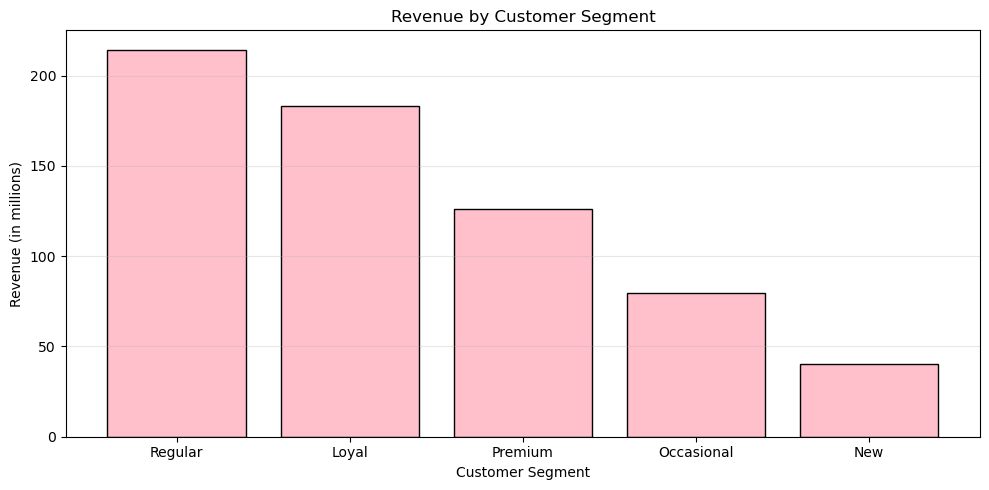

In [29]:

# Plot revenue by customer segment
plt.figure(figsize=(10, 5))

plt.bar(
    segment_revenue.index,
    segment_revenue.values / 1e6,
    color="pink",
    edgecolor="black"
)

plt.title("Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue (in millions)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("../charts/revenue_by_customer_segment.png",
            dpi=300, bbox_inches="tight")

plt.show()



**Observations – Revenue by Customer Segment**

1. Regular customers generate the highest revenue, approximately ₹214.40 million.
2. Loyal customers rank second, contributing approximately ₹183.41 million.
3. Premium customers generate approximately ₹126.04 million.
4. Occasional customers contribute approximately ₹79.38 million.
5. New customers generate the lowest revenue, approximately ₹40.01 million.
6. Regular and Loyal customers together contribute a major share of total sales revenue.



# 11. Task 8 – Observations and Findings



### 11.1 Key Findings

1. **Customer Demographics:** The dataset contains 2,000 customers, with an average age of 41.37 years. Male customers (1,123) slightly outnumber female customers (877).

2. **Monthly Sales Trends:** Monthly sales revenue shows an overall increasing trend from January 2025 to August 2026. August 2026 recorded the highest monthly revenue of approximately ₹41.77 million.

3. **Quarterly Sales Trends:** Quarterly revenue increased across the complete quarters, reaching approximately ₹114.12 million in Q2 2026.

4. **Best-Selling Products:** UrbanX Appliances 2 is the top-selling product, with 546 units sold, followed closely by Nova Smartphones 1 with 545 units.

5. **Revenue by Category:** Home & Kitchen generates the highest category revenue, approximately ₹160.14 million, while Sports generates the lowest, approximately ₹112.04 million.

6. **Correlation Analysis:** Unit Price has the strongest positive correlation with Revenue (0.68), followed by Quantity (0.60).

7. **Customer Segments:** Regular customers generate the highest revenue (approximately ₹214.40 million), followed by Loyal customers (approximately ₹183.41 million).



# 12. Task 9 – Business Recommendations



### 12.1 Actionable Business Recommendations

1. **Strengthen Customer Retention:** Regular and Loyal customers generate the highest revenue. The business should introduce loyalty rewards, exclusive offers and personalised promotions to encourage repeat purchases.

2. **Improve Category Performance:** Home & Kitchen generates the highest revenue, while Sports generates the lowest. The business should maintain the availability of popular Home & Kitchen products and investigate opportunities to improve Sports category sales through targeted promotions and product offers.

3. **Improve Customer Acquisition:** New customers contribute the lowest revenue among the customer segments. The business should introduce first-purchase discounts, welcome offers and targeted marketing campaigns to encourage new customers to make repeat purchases.


# 13. Project Conclusion

The Exploratory Data Analysis of Retail Sales Data helped identify important patterns in customer behaviour, sales performance, and product categories.

The analysis showed an overall increase in monthly sales revenue, with August 2026 recording the highest revenue. Home & Kitchen was the highest revenue-generating product category, while Regular customers contributed the largest share of revenue.

Statistical analysis and visualisations helped understand customer demographics, product demand, and relationships between numerical variables.

Based on these findings, business recommendations were provided to improve customer retention, strengthen product category performance, and attract new customers.

Overall, this project demonstrates how Python and its data analysis libraries can be used to explore retail data and generate meaningful business insights.